# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**:
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['china', 'europe', 'japan', 'korea', 'us']

Stock counts by market:
  CHINA: 557 stocks
  EUROPE: 599 stocks
  JAPAN: 495 stocks
  KOREA: 295 stocks
  US: 2,963 stocks


In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


---
## Historical Analysis

### Factor Time Series Performance

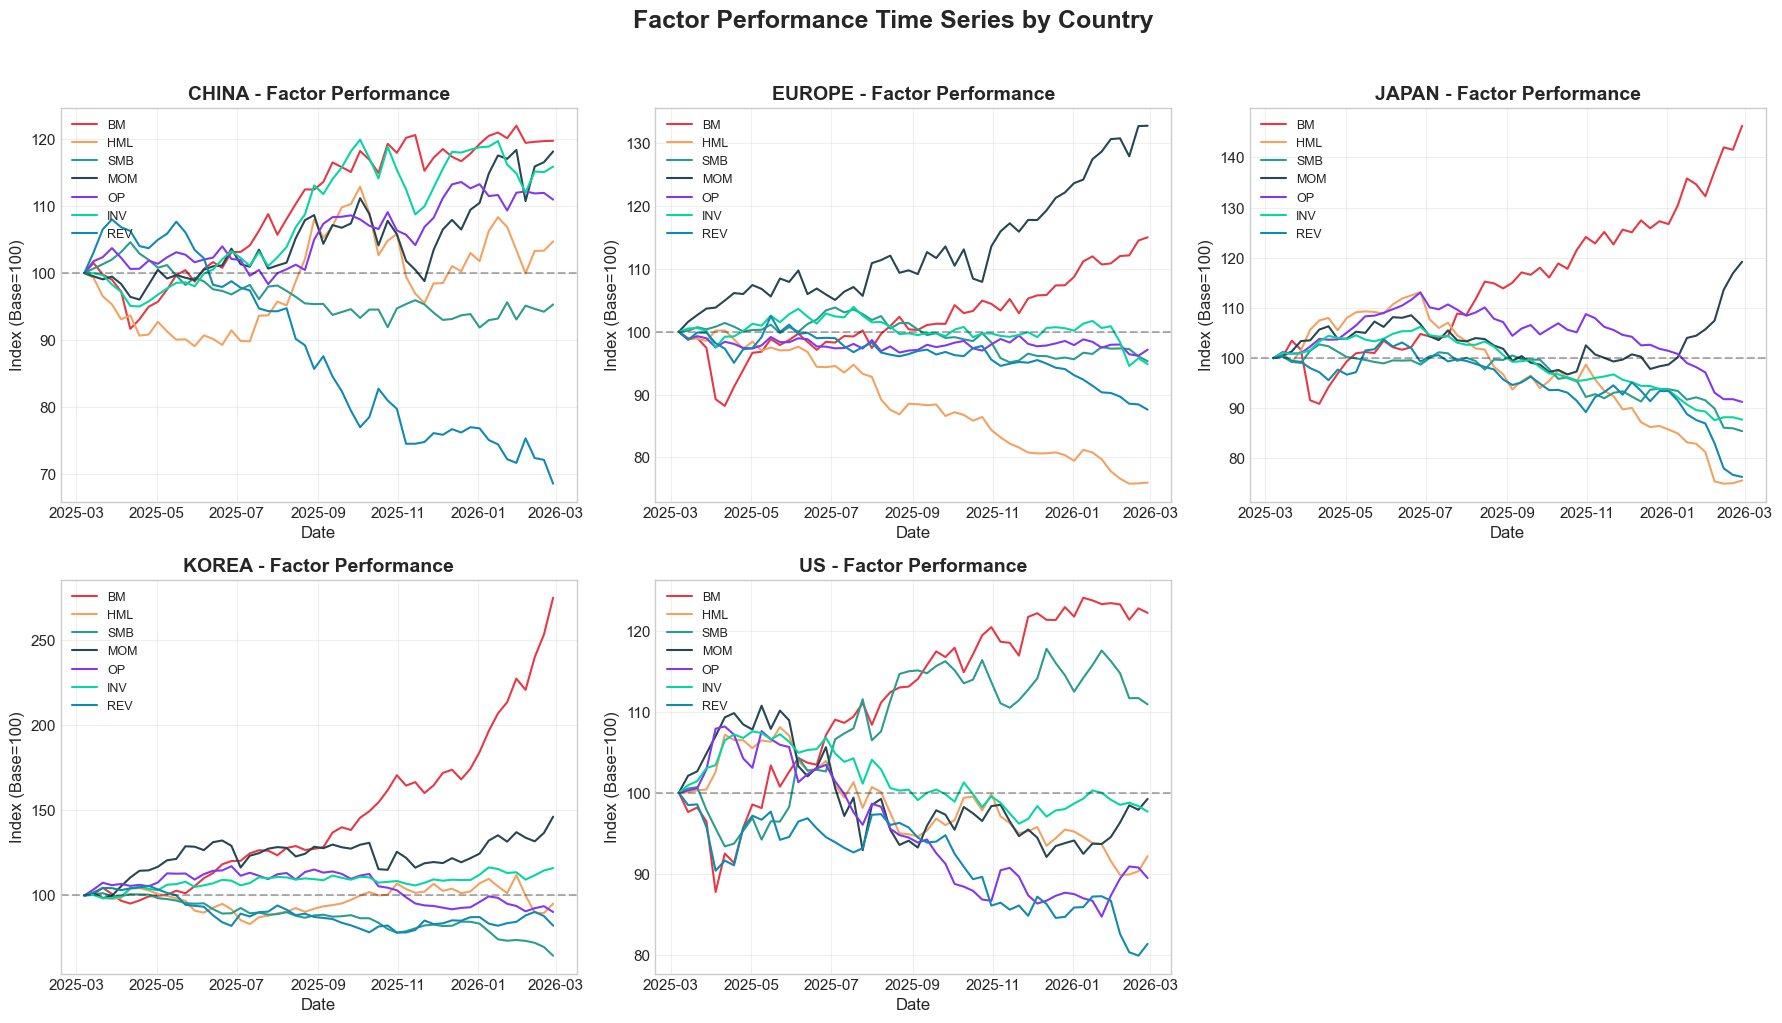

In [5]:
# Plot factor time series for each country
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [6]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country])
    display(stats.style.format('{:.3f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,19.780,19.320,13.375,1.444,-9.699,-1.010,1.512
HML,4.738,6.434,18.668,0.345,-15.404,-0.158,-0.217
SMB,-4.694,-4.468,9.391,-0.476,-12.199,0.094,-0.167
MOM,18.187,18.527,17.237,1.075,-11.149,-0.415,0.238
OP,10.984,11.190,10.647,1.051,-5.448,0.371,0.213
INV,15.913,15.945,13.302,1.199,-9.311,-0.165,-0.608
REV,-31.484,-36.870,17.671,-2.086,-36.572,0.163,0.352



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,15.053,15.251,13.661,1.116,-11.807,-1.851,7.630
HML,-24.016,-27.577,8.445,-3.266,-24.349,-0.059,0.714
SMB,-4.683,-4.701,6.177,-0.761,-8.403,-0.406,0.200
MOM,32.817,29.878,13.287,2.249,-4.971,-0.033,0.919
OP,-2.853,-2.787,5.776,-0.482,-3.813,-0.224,-0.683
INV,-5.144,-5.045,8.259,-0.611,-9.055,-0.810,1.384
REV,-12.407,-13.166,8.128,-1.620,-14.543,0.657,1.345



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,46.324,40.429,17.161,2.356,-12.169,-1.670,6.757
HML,-24.385,-27.270,15.234,-1.790,-33.733,-0.433,0.931
SMB,-14.560,-15.607,9.140,-1.708,-16.843,-0.396,1.660
MOM,19.216,18.739,12.756,1.469,-10.867,0.890,1.450
OP,-8.734,-8.844,9.724,-0.910,-19.300,-0.256,0.877
INV,-12.257,-13.136,6.039,-2.175,-17.530,-0.048,-0.582
REV,-23.683,-26.603,13.373,-1.989,-26.440,0.007,1.425



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,174.580,106.650,23.384,4.561,-8.825,-0.120,-0.591
HML,-4.724,-1.039,28.042,-0.037,-20.242,-0.284,1.278
SMB,-35.295,-42.991,15.536,-2.767,-36.156,-0.789,0.968
MOM,46.192,42.559,27.244,1.562,-13.005,-0.846,2.404
OP,-9.682,-8.770,18.036,-0.486,-22.928,-0.164,-0.316
INV,16.057,16.011,12.853,1.246,-6.190,0.197,0.240
REV,-17.664,-17.401,22.085,-0.788,-25.912,0.509,0.741



US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,22.221,21.905,16.839,1.301,-12.271,-0.872,4.685
HML,-7.831,-7.610,11.935,-0.638,-16.887,0.264,0.097
SMB,10.920,11.631,14.696,0.791,-7.271,0.305,0.537
MOM,-0.758,0.664,17.068,0.039,-16.873,-0.482,0.667
OP,-10.549,-10.462,13.543,-0.773,-21.718,0.834,0.978
INV,-2.338,-2.021,8.940,-0.226,-10.591,0.258,0.237
REV,-18.677,-20.037,14.254,-1.406,-20.137,0.020,1.443


### Factor Correlation Analysis

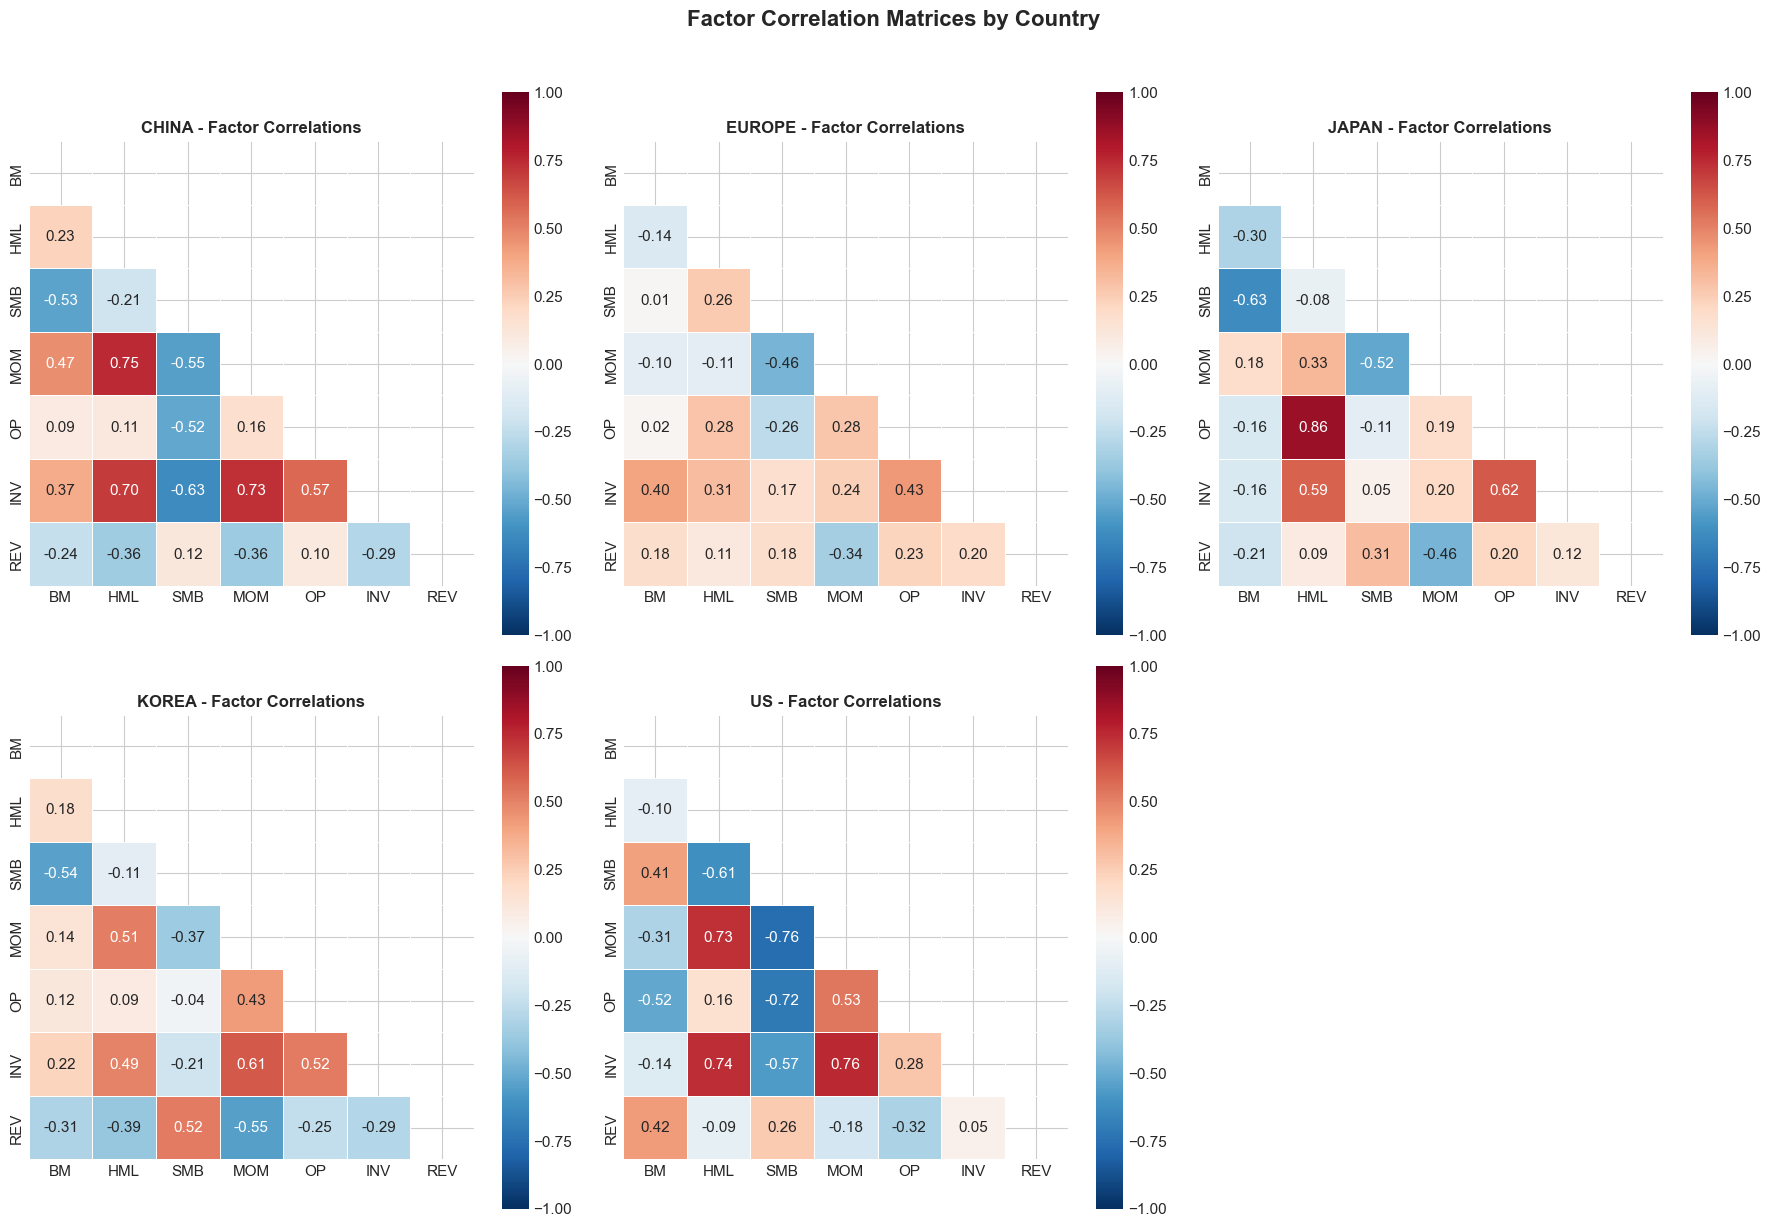

In [7]:
# Factor correlation matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Stock Market(Country) Analysis

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
CHINA,-1.2557
EUROPE,-0.1383
JAPAN,-0.1476
KOREA,1.2823
US,-0.4587



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
CHINA,13.3,-1.26,54.8%,1.2370,0.006
EUROPE,38.5,-0.14,67.1%,1.6430,0.053
JAPAN,42.2,-0.15,81.8%,0.8199,0.055
KOREA,91.2,1.28,99.0%,4.1838,0.260
US,26.4,-0.46,55.1%,4.2076,0.023



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


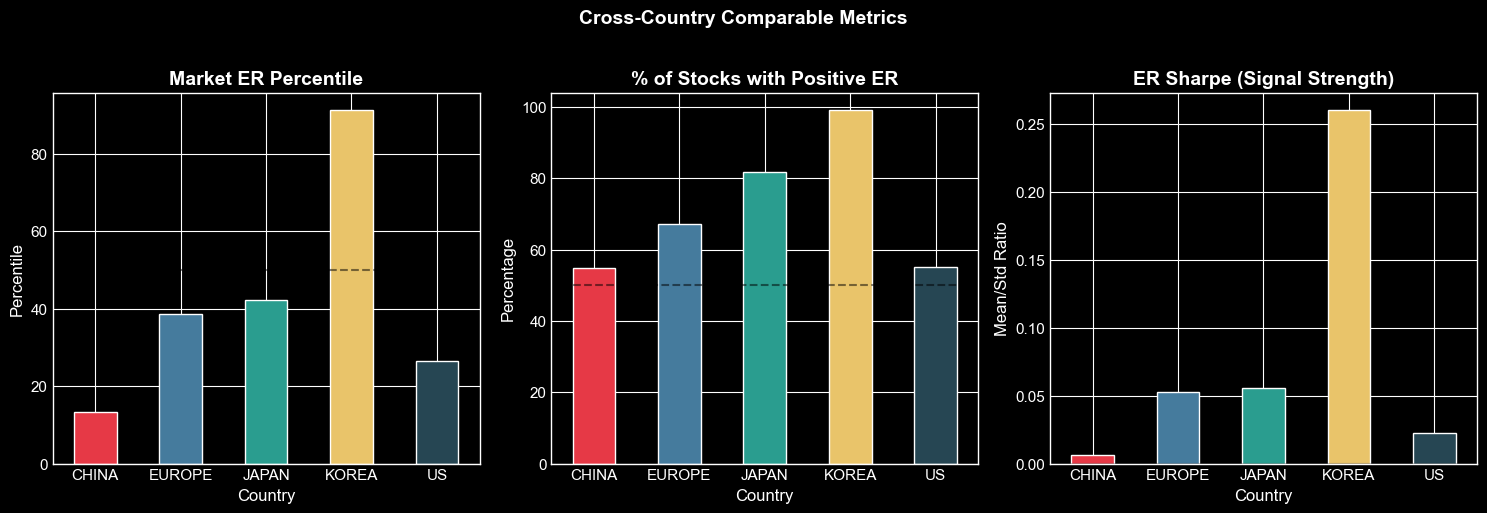

In [59]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.4f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.4f}',
    'ER Sharpe (mean/std)': '{:.3f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Factor Analysis

### Factor Expected Returns

In [62]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
CHINA,-1.21,-0.05,-0.26,0.55,-2.38,0.88
EUROPE,-0.14,-1.00,-0.06,-2.43,-0.52,0.70
JAPAN,-0.14,-1.33,-1.53,0.13,-1.17,0.22
KOREA,1.41,0.23,0.33,2.25,-0.40,-3.04
US,-0.43,-0.95,-0.30,-1.39,0.03,0.85



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  SMB  : -0.08 NEUTRAL → 
  BM   : -0.10 NEUTRAL → 
  MOM  : -0.18 NEUTRAL → █
  INV  : -0.37 NEUTRAL → ███
  HML  : -0.62 WEAK ↓ ██████
  OP   : -0.89 WEAK ↓ ████████


### Factor Premium Comparison

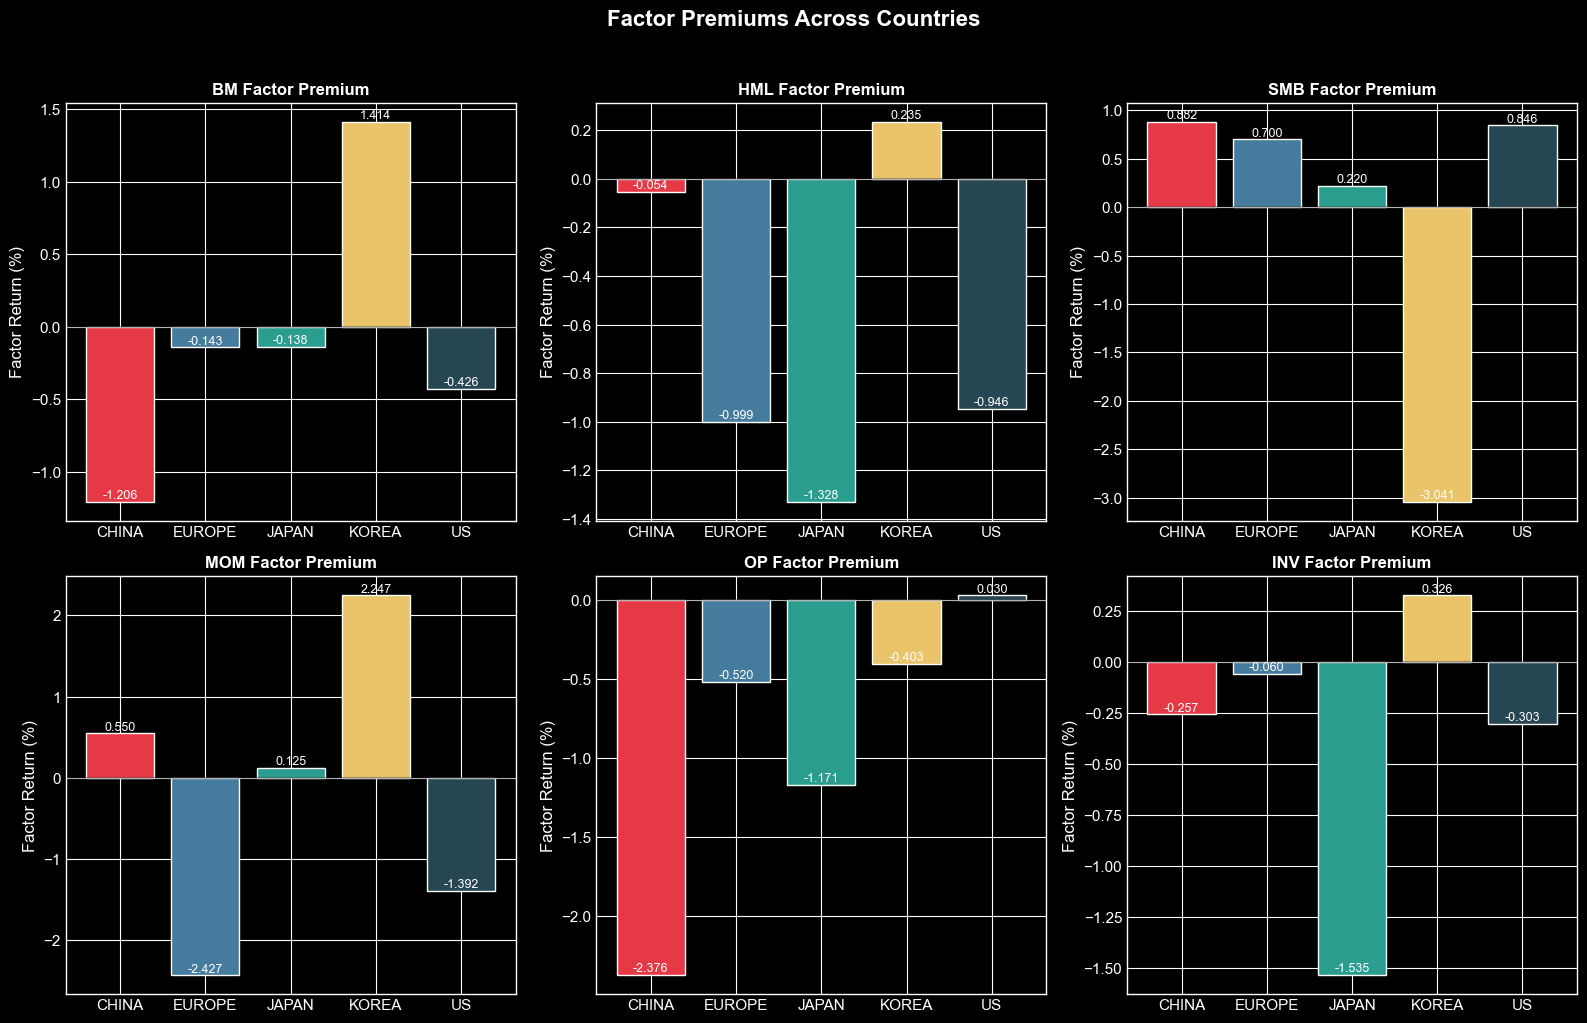

In [61]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Sector Analysis

### Sector Factor Exposures

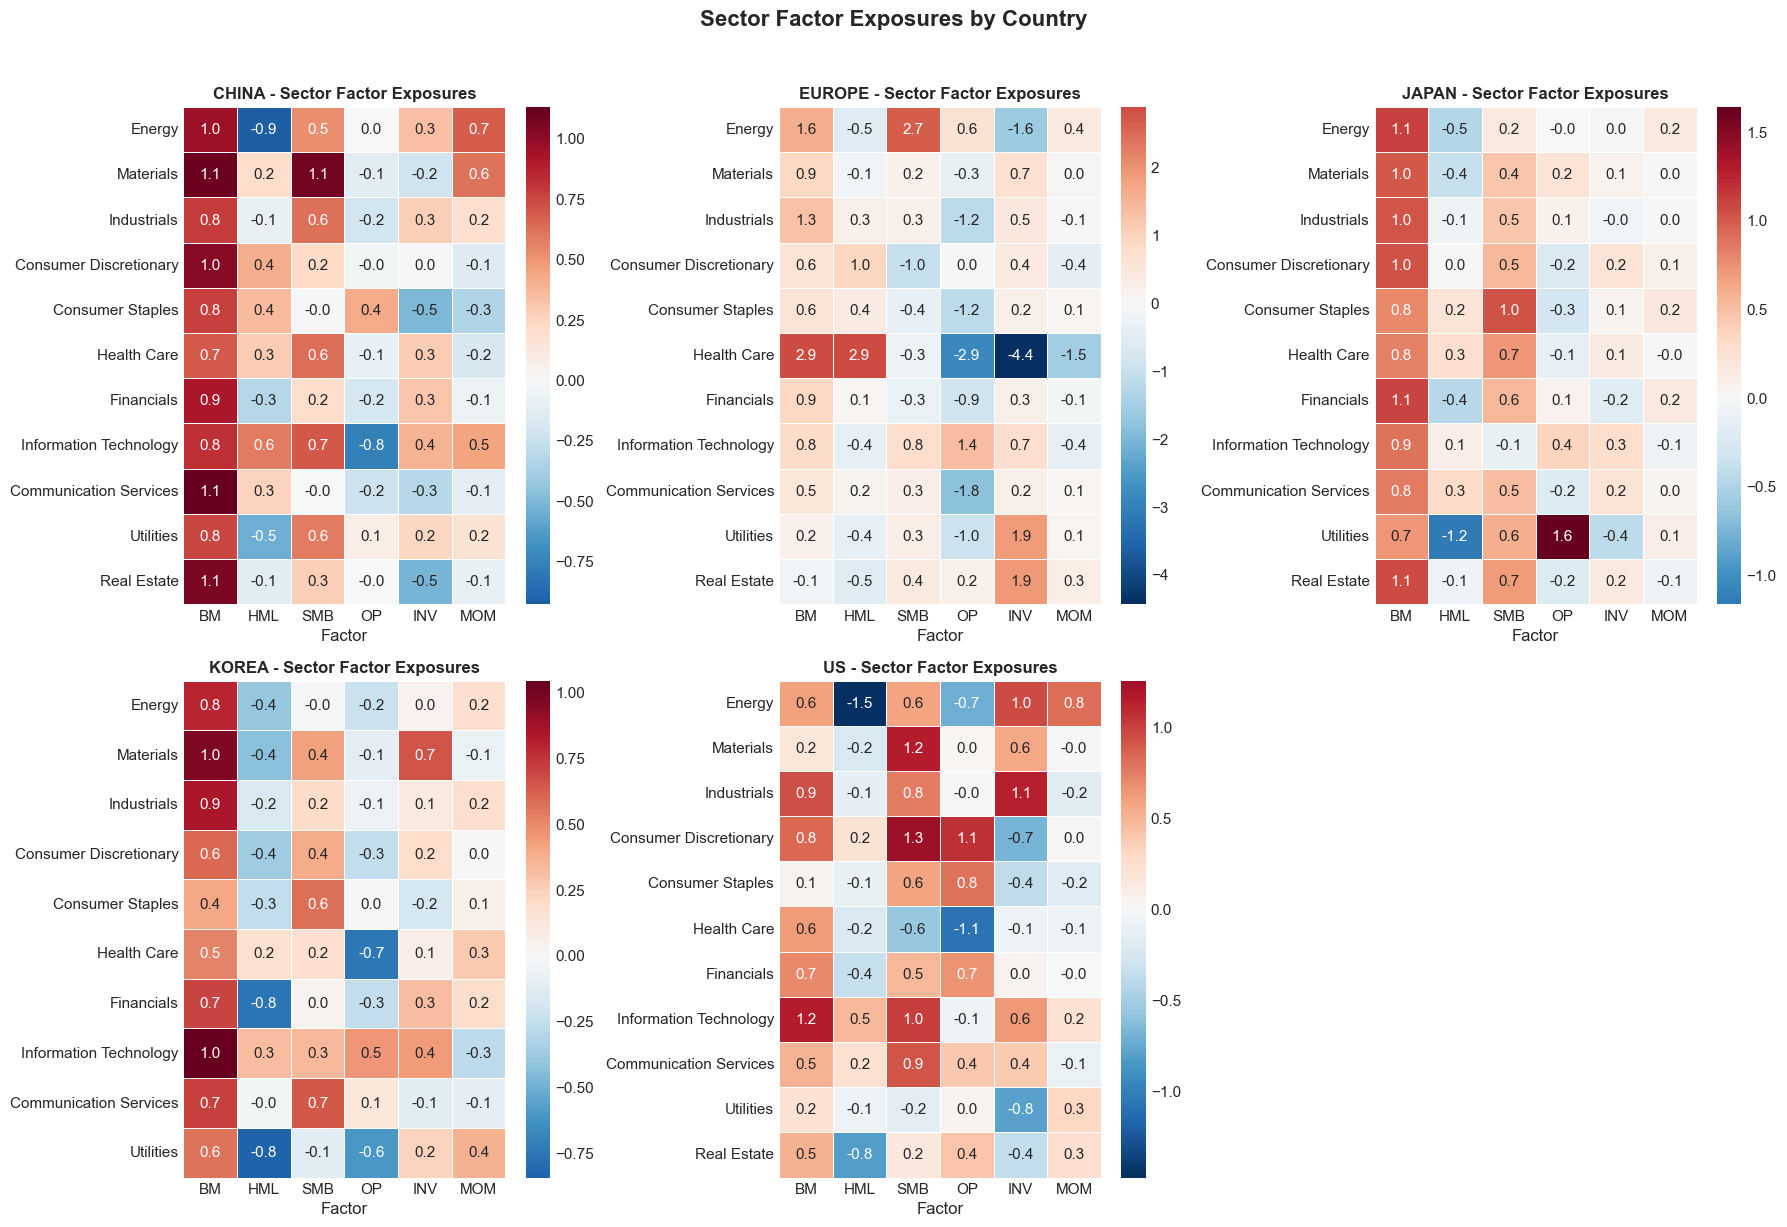

In [14]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [63]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,CHINA,EUROPE,JAPAN,KOREA,US
Sector,,,,,
Energy,-3.67,-0.03,0.02,0.90,0.31
Materials,-1.11,0.01,-0.15,0.82,-0.20
Industrials,-1.33,-0.25,-0.14,1.08,-0.01
Consumer Discretionary,-1.84,-0.72,-0.19,1.00,-0.76
Consumer Staples,-1.48,-0.54,-0.35,0.32,0.53
Health Care,-0.29,0.15,-0.36,-0.20,-0.78
Financials,-1.14,0.03,0.00,0.72,-0.48
Information Technology,-0.41,-0.09,-0.11,1.53,-0.58
Communication Services,-0.89,-0.18,-0.29,0.67,-0.12



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Information Technology   : +0.07 NEUTRAL 
  Materials                : -0.13 NEUTRAL █
  Industrials              : -0.13 NEUTRAL █
  Communication Services   : -0.16 NEUTRAL █
  Financials               : -0.17 NEUTRAL █
  Real Estate              : -0.25 NEUTRAL ██
  Health Care              : -0.29 NEUTRAL ██
  Utilities                : -0.30 NEUTRAL ██
  Consumer Staples         : -0.30 UNDERWEIGHT ███
  Energy                   : -0.49 UNDERWEIGHT ████
  Consumer Discretionary   : -0.50 UNDERWEIGHT █████


### Top Equities by country

In [69]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,CNE1000020V4,Victory Giant Technology HuiZhou Co Ltd,Info Tech,3.46,20.65,0.17,"142,222"
13,HK0000218211,Hua Hong Semiconductor Ltd,Info Tech,3.42,23.88,0.14,"119,215"
9,CNE100002CC3,Shenzhen Envicool Technology Co Ltd,nan,3.10,20.33,0.15,"54,931"
15,CNE100004413,VeriSilicon Microelectronics Shanghai Co Ltd,Info Tech,3.06,21.58,0.14,"66,829"
0,CA16890P1036,China Gold International Resources Corp Ltd,nan,3.01,15.89,0.19,"43,402"
10,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,2.85,18.98,0.15,"516,667"
16,CNE100006JG0,Laopu Gold Co Ltd,Consumer Disc.,2.59,18.75,0.14,"34,397"
2,CNE1000030S9,GigaDevice Semiconductor Inc,Info Tech,2.47,14.70,0.17,"188,898"
7,CNE000000D24,Inner Mongolia Xingye Silver&Tin Mining Co Ltd,nan,2.35,15.01,0.16,"67,690"
5,CNE000000BL1,Guangdong Hec Technology Holding Co Ltd,Materials,2.33,14.46,0.16,"36,827"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
1,PLKGHM000017,KGHM Polska Miedz SA,Materials,4.73,10.35,0.46,"10,768"
0,DE000BAY0017,Bayer AG,Health Care,4.56,9.70,0.47,"43,693"
10,GB00B2QPKJ12,Fresnillo PLC,Materials,4.53,14.33,0.32,"7,868"
18,CH0311864901,VAT Group AG,Industrials,3.62,12.64,0.29,"14,736"
4,SE0020050417,Boliden AB,Materials,3.36,9.55,0.35,"16,606"
14,DE0006766504,Aurubis AG,Materials,3.00,10.03,0.30,"4,925"
15,IT0005495657,Saipem SpA,Energy,2.91,9.90,0.29,"4,053"
2,IL0011284465,Plus500 Ltd,Financials,2.82,7.13,0.40,"3,292"
6,FR0000131104,BNP Paribas SA,Financials,2.73,7.89,0.35,"89,164"
11,LU0075646355,Subsea 7 SA,Energy,2.52,8.17,0.31,"4,896"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
15,JP3891600003,Mitsui E&S Co Ltd,Industrials,2.85,16.66,0.17,"663,299"
12,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,2.71,15.32,0.18,"1,092,420"
4,JP3842400008,Hokuhoku Financial Group Inc,Financials,1.78,9.11,0.20,"577,781"
3,JP3309000002,Penta-Ocean Construction Co Ltd,Industrials,1.69,8.51,0.20,"445,998"
0,JP3230600003,Kandenko Co Ltd,Industrials,1.57,6.21,0.25,"566,474"
1,JP3443600006,Taisei Corp,Industrials,1.48,6.80,0.22,"2,514,762"
2,JP3210200006,Kajima Corp,Industrials,1.48,7.30,0.20,"2,965,599"
13,JP3877600001,Marubeni Corp,Industrials,1.46,8.31,0.18,"7,529,635"
7,JP3358800005,Shimizu Corp,Industrials,1.46,7.91,0.18,"1,431,958"
14,JP3263000006,Kinden Corp,Industrials,1.39,7.96,0.18,"763,073"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7402340004,SK Square Co Ltd,Industrials,11.25,18.30,0.61,"51,049,244"
17,KR7240810002,Wonik IPS Co Ltd,Info Tech,9.72,21.20,0.46,"3,314,522"
0,KR7000660001,SK Hynix Inc,Info Tech,9.40,14.09,0.67,"519,004,319"
9,KR7042700005,Hanmi Semiconductor Co Ltd,Info Tech,9.33,18.57,0.50,"8,880,956"
3,KR7006800007,Mirae Asset Securities Co Ltd,Financials,8.82,15.09,0.58,"12,215,835"
5,KR7039490008,Kiwoom Securities Co Ltd,Financials,8.19,14.90,0.55,"6,631,681"
4,KR7298040007,Hyosung Heavy Industries Corp,Industrials,8.17,14.75,0.55,"12,398,516"
15,KR7039030002,EO Technics Co Ltd,Info Tech,7.81,16.96,0.46,"3,162,179"
13,KR7000990002,DB HiTek Co Ltd,Info Tech,7.41,15.84,0.47,"3,515,436"
12,KR7010120004,LS Electric Co Ltd,Industrials,7.10,15.08,0.47,"8,668,144"



----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,US6078281002,Modine Manufacturing Co,Industrials,11.94,17.80,0.67,"9,574"
5,US87305R1095,TTM Technologies Inc,Info Tech,11.21,17.46,0.64,"9,921"
17,US60770K1079,Moderna Inc,Health Care,9.40,18.81,0.50,"15,966"
4,US55405Y1001,MACOM Technology Solutions Holdings Inc,Info Tech,8.44,12.80,0.66,"13,949"
1,US2193501051,Corning Inc,Info Tech,7.03,9.52,0.74,"75,828"
14,US36828A1016,GE Vernova Inc,Industrials,6.49,12.79,0.51,"195,658"
8,US83443Q1031,Solstice Advanced Materials Inc,nan,6.49,11.28,0.58,"9,803"
6,US5398301094,Lockheed Martin Corp,Industrials,4.59,7.32,0.63,"145,807"
10,US6153942023,Moog Inc,Industrials,4.09,7.34,0.56,"9,468"
0,US8718291078,Sysco Corp,Consumer Staples,4.07,5.41,0.75,"40,069"
